In [28]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [29]:
%pip install numpy
%pip install pandas
%pip install joblib
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrad

References

District data -> https://data.humdata.org/dataset/cod-ab-uga

## Source data

The data files in `data/` stand in for the SACCO's core banking system. They are produced by
`SyntheticCoreBanking`, which simulates members saving and borrowing over two years. Every file
comes from the same simulated history, so balances, arrears, promises and collection activity
all agree with each other. Set `REGENERATE = True` to rebuild them; the fixed seed gives the
same files every time.

In [30]:
from src.synthetic_core_banking import SyntheticCoreBanking, GeneratorSettings

REGENERATE = False      # set to True to rebuild every file in data/ from the simulation

if REGENERATE:
    counts = SyntheticCoreBanking(GeneratorSettings(seed=2026)).write("data")
    print(counts)

### Data Load
***Load data from data files*** 

Todo: ill insert the explanation later


In [31]:
from src.csv_import import CsvImport

importer = CsvImport()

#Load KB and customer data
kb = importer.load_dir_data("kb")
cust_data = importer.load_dir_data("data")



## Customer List

***To do:Add descriptions of this section***

In [32]:
from datetime import date
from src.display.customer_list import CustomerList

CustomerList(
    cust_data["customer"]["rows"], date.today(), 25, 2,
    address_rows=cust_data["address"]["rows"],
    contact_rows=cust_data["contact"]["rows"],
    location_rows=kb["locations"]["rows"],
).show()

## Cases

Every loan case, most overdue first. Filter by account number, customer, loan type, status,
days past due (DPD) or outstanding balance.

In [33]:
from src.display.case_list import CaseList

CaseList(cust_data["case"]["rows"], cust_data["customer"]["rows"], kb["loan_types"]["rows"], list_page_size=25, filter_cols_per_row=2).show()

## Collections policy

The rules the system follows each day are kept in `configs/policy.json`, not in the code,
so they can change without changing any classes. The policy is checked when it loads,
so a mistake stops the notebook with a clear message instead of treating customers the wrong way.

In [34]:
from src.policy import Policy

policy = Policy.load("configs/policy.json", treatment_type_rows=kb["treatment_type"]["rows"])

### Delinquency buckets

Loans are grouped by how many days they are overdue (DPD). Every loan falls in exactly one bucket.

In [35]:
from src.display.bucket_list import BucketList

BucketList(policy, list_page_size=25, filter_cols_per_row=3).show()

### Profile rules

The rules are checked from the top. The first rule whose conditions all match decides the
customer's profile, and anyone no rule matches gets the default profile at the bottom.

In [36]:
from src.display.profile_rule_list import ProfileRuleList

ProfileRuleList(policy, list_page_size=25, filter_cols_per_row=3).show()

### Treatment matrix

The action taken for each profile and bucket. A combination that isn't listed gets no treatment.
"Fallback" is used when the main treatment can't be, for example an email when a customer
has no valid mobile number for an SMS.

In [37]:
from src.display.treatment_list import TreatmentList

TreatmentList(
    policy, list_page_size=25, filter_cols_per_row=3,
    treatment_type_rows=kb["treatment_type"]["rows"],
).show()

### Channel limits

How often each channel may be used to contact the same customer. These are the SACCO's own
policy settings, not legal limits.

In [38]:
from src.display.channel_limit_list import ChannelLimitList

ChannelLimitList(policy, list_page_size=25, filter_cols_per_row=3).show()

### General compliance rules

Rules that apply to every contact, whatever the channel: when customers may be contacted,
and which cases are never treated.

In [39]:
from src.display.general_rule_list import GeneralRuleList

GeneralRuleList(policy, list_page_size=25, filter_cols_per_row=3).show()

## Contact history

Every SMS, email and call made to customers, newest first, with the number or email used
and the outcome. Filter by account, customer, month, channel, outcome or words in the notes.

In [40]:
from src.display.contact_history import ContactHistory

ContactHistory(
    cust_data["contact_history"]["rows"],
    cust_data["case"]["rows"],
    cust_data["customer"]["rows"],
    contact_rows=cust_data["contact"]["rows"],
    list_page_size=25,
    filter_cols_per_row=3,
).show()

## Payment history

Every payment received, newest first. "Against PTP" shows whether the payment was made
against a promise to pay. Filter by account, customer, receipt reference, month, channel,
status or amount.

In [41]:
from src.display.payment_history import PaymentHistory

PaymentHistory(
    cust_data["payment_history"]["rows"],
    cust_data["case"]["rows"],
    cust_data["customer"]["rows"],
    list_page_size=25,
    filter_cols_per_row=3,
).show()

## Promise-to-pay history

Every promise to pay, latest promised date first. "Paid %" shows how much of each promise
was paid; over 100 means the customer paid more than promised. Filter by account, customer,
month promised, status, promised amount or paid %.

In [42]:
from src.display.ptp_history import PtpHistory

PtpHistory(
    cust_data["ptp"]["rows"],
    cust_data["case"]["rows"],
    cust_data["customer"]["rows"],
    list_page_size=25,
    filter_cols_per_row=3,
).show()

## Treatment history

Every collection treatment started on a case, newest first: what was done, who it was
assigned to, and how overdue the loan was when it started. "Days" is how long the treatment
ran, or has been running so far. Filter by account, customer, start month, treatment,
status, who it's assigned to, DPD or arrears at the start, or duration.

In [43]:
from src.display.treatment_history import TreatmentHistory

TreatmentHistory(
    cust_data["treatment_history"]["rows"],
    cust_data["case"]["rows"],
    cust_data["customer"]["rows"],
    list_page_size=25,
    filter_cols_per_row=3,
    treatment_type_rows=kb["treatment_type"]["rows"],
).show()

## Risk model

The model estimates each loan's probability of default (PD): the chance it reaches 90 days
past due within the next 6 months.

Each training row is one open loan at the end of one month, built only from what was known
that day:

- repayment history
- current DPD and MIA
- debt-to-income
- savings habits
- guarantor strength

The model learns from earlier months and is tested on later ones it never saw, the same way
it will be used: trained on the past, then used on today's loans.

In [44]:
from datetime import date
import pandas as pd
from src.risk.feature_builder import FeatureBuilder

AS_OF = date(2026, 10, 22)

builder = FeatureBuilder(cust_data, kb, as_of=AS_OF, default_dpd=90, outcome_months=6)
rows = builder.training_set()

print(f"{len(rows):,} loan-months, {rows['defaulted'].sum():,} went on to default "
      f"({rows['defaulted'].mean():.1%})")
rows[FeatureBuilder.NUMERIC].describe().T[["mean", "min", "max"]].round(2)

8,906 loan-months, 713 went on to default (8.0%)


,mean,min,max
dpd,3.33,0.00,89.00
mia,0.13,0.00,11.56
outstanding_ratio,0.73,0.00,1.00
months_on_book,4.49,0.00,17.80
dti,0.36,0.06,1.48
monthly_income,966174.49,150000.00,4230000.00
savings_months_12,8.51,0.00,12.00
savings_to_income,1.64,0.00,3.63
guarantor_count,1.27,0.00,3.00
security_cover,1.22,0.00,3.00


In [45]:
from src.risk import LogisticPdModel

SPLIT_DATE = pd.Timestamp("2025-12-31")      # train on earlier months, test on later ones
train = rows[rows["observed_on"] < SPLIT_DATE]
test = rows[rows["observed_on"] >= SPLIT_DATE]
print(f"Training: {len(train):,} rows ({train['defaulted'].sum()} defaults), "
      f"months up to {train['observed_on'].max():%b %Y}")
print(f"Testing:  {len(test):,} rows ({test['defaulted'].sum()} defaults), "
      f"{test['observed_on'].min():%b %Y} to {test['observed_on'].max():%b %Y}")

model = LogisticPdModel(FeatureBuilder.NUMERIC, FeatureBuilder.CATEGORICAL).fit(train)
model.coefficients().head(12).round(3)

Training: 6,196 rows (539 defaults), months up to Nov 2025
Testing:  2,710 rows (174 defaults), Dec 2025 to Mar 2026


,feature,coefficient,effect
0,repayment_frequency_weekly,-1.193,lowers risk
1,product_salary,-1.039,lowers risk
2,product_housing,-1.016,lowers risk
3,product_school_fees,0.935,raises risk
4,repayment_frequency_monthly,0.884,raises risk
5,product_emergency,0.819,raises risk
6,mia,0.606,raises risk
7,employment_type_id_SALARIED,-0.526,lowers risk
8,employment_type_id_CASUAL,0.442,raises risk
9,savings_months_12,-0.434,lowers risk


AUC on the test months: 0.911  (0.5 = guessing, 1.0 = perfect ranking)


band,loans,defaults,predicted PD %,actual default rate %
A,542,5,0.700000,0.900000
B,542,1,1.800000,0.200000
C,542,5,3.200000,0.900000
D,542,18,5.400000,3.300000
E,542,145,28.900000,26.800000


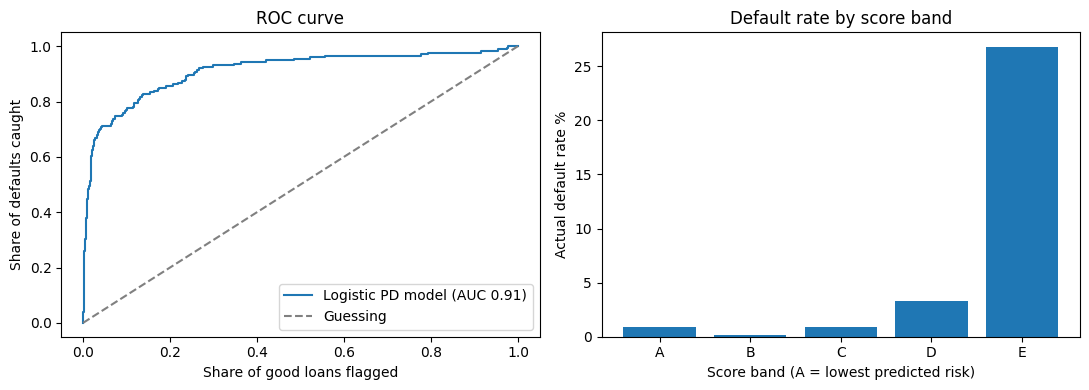

In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

evaluation = model.evaluate(test, bands=5)
print(f"AUC on the test months: {evaluation.auc:.3f}  "
      f"(0.5 = guessing, 1.0 = perfect ranking)")

bands = evaluation.bands.assign(
    average_pd=lambda b: (100 * b["average_pd"]).round(1),
    default_rate=lambda b: (100 * b["default_rate"]).round(1),
)[["band", "loans", "defaults", "average_pd", "default_rate"]].rename(
    columns={"average_pd": "predicted PD %", "default_rate": "actual default rate %"})
display(bands.style.hide(axis="index"))

fpr, tpr, _ = roc_curve(test["defaulted"], model.predict_pd(test))
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.plot(fpr, tpr, label=f"Logistic PD model (AUC {evaluation.auc:.2f})")
left.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Guessing")
left.set(xlabel="Share of good loans flagged", ylabel="Share of defaults caught", title="ROC curve")
left.legend()
right.bar(bands["band"], bands["actual default rate %"])
right.set(xlabel="Score band (A = lowest predicted risk)", ylabel="Actual default rate %",
          title="Default rate by score band")
plt.tight_layout()
plt.show()

In [47]:
from pathlib import Path

MODEL_PATH = Path("src/models/pd_model.joblib")

final_model = LogisticPdModel(FeatureBuilder.NUMERIC, FeatureBuilder.CATEGORICAL).fit(rows)
final_model.save(MODEL_PATH)
print(f"Saved to {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1024:.0f} KB), trained on all {len(rows):,} rows")

Saved to src/models/pd_model.joblib (5 KB), trained on all 8,906 rows


### What the results show

The model ranks risk well on months it never saw (AUC about 0.91). Almost all defaults fall in
band E, where about 1 in 4 loans defaulted, against under 1 in 100 in bands A to C.

Current arrears (DPD and MIA) are strong signals, as expected. Without them, the model still
reaches an AUC of about 0.81 using only income, savings habits, guarantors and the loan type,
so the other features carry real information too.

The data is synthetic, so these figures show that the method works, not how a real SACCO's
loans would behave.